In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
"""
Compression Feature Analysis for Histopathology Datasets
==========================================================
Reproduces the 7-file analysis from BreakHis for MHIST, BACH, NCT-CRC.

Outputs per dataset:
  1. basic_statistics.csv
  2. texture_features.csv
  3. frequency_features.csv
  4. feature_importance.csv
  5. feature_degradation.csv
  6. compression_impact.csv
  7. class_discriminative_features.csv
  8. model_recommendations.txt

Run in Google Colab. Mount Drive first.
"""

# ============================================================
# Cell 1: Install dependencies
# ============================================================
!pip install scikit-image --quiet

# ============================================================
# Cell 2: Imports
# ============================================================
import os
import glob
import numpy as np
import pandas as pd
from PIL import Image
from collections import defaultdict
import warnings
import time
warnings.filterwarnings('ignore')

from skimage.feature import graycomatrix, graycoprops, local_binary_pattern, canny
from skimage.color import rgb2gray, rgb2hsv
from skimage.filters import sobel
from scipy import stats, ndimage
from scipy.fft import fft2, fftshift

# ============================================================
# Cell 3: Configuration
# ============================================================

# --- EDIT THESE ---
DATASET_NAME = 'MHIST'  # Change to: 'MHIST', 'BACH', 'NCT-CRC'

BASE_DIR = '/content/drive/MyDrive/MHIST_PLOS_ONE/MHIST_Split'  # Where CR folders live

# Class mapping: how to determine class from folder structure.
# Set to 'subfolder' if images are in class subfolders (e.g., CR1_original/HP/, CR1_original/SSA/)
# Set to 'filename' if class is encoded in filename
# Set to a dict for manual mapping
CLASS_MODE = 'subfolder'

# If CLASS_MODE = 'filename', provide a function:
# def get_class_from_filename(filename):
#     if 'benign' in filename.lower(): return 'benign'
#     return 'malignant'

# Binary grouping for feature importance (maps raw classes to 2 groups)
# Set to None if classes are already binary
BINARY_GROUPS = None
# Example for BACH: BINARY_GROUPS = {'Normal': 'benign', 'Benign': 'benign',
#                                     'InSitu': 'malignant', 'Invasive': 'malignant'}
# Example for NCT-CRC with 9 classes - you may want to skip feature_importance
# or group as: BINARY_GROUPS = {'NORM': 'normal', 'ADI': 'normal', 'BACK': 'normal',
#                                'DEB': 'abnormal', 'LYM': 'abnormal', 'MUC': 'abnormal',
#                                'MUS': 'normal', 'STR': 'normal', 'TUM': 'abnormal'}

CR_FOLDERS = ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000']
CR_LABELS = ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1K']

N_SAMPLES = 500         # Images to sample for analysis (set lower for quick test)
RANDOM_SEED = 42

OUTPUT_DIR = f'/content/drive/MyDrive/JPEG2000_Paper_Final/feature_analysis/{DATASET_NAME}'

# ============================================================
# Cell 4: Image discovery and sampling
# ============================================================

def find_images_with_class(base_dir, cr_folder, class_mode='subfolder'):
    """Find images and their class labels in a CR folder."""
    cr_path = os.path.join(base_dir, cr_folder)
    if not os.path.isdir(cr_path):
        print(f"  ❌ Not found: {cr_path}")
        return []

    extensions = ('*.png', '*.PNG', '*.jpg', '*.JPG', '*.jpeg', '*.tif', '*.tiff')
    results = []

    for ext in extensions:
        for path in glob.glob(os.path.join(cr_path, '**', ext), recursive=True):
            rel = os.path.relpath(path, cr_path)
            filename = os.path.basename(path)

            if class_mode == 'subfolder':
                # Class from first subfolder level
                parts = rel.split(os.sep)
                if len(parts) > 1:
                    cls = parts[0]
                else:
                    cls = 'unknown'
            elif class_mode == 'filename':
                cls = get_class_from_filename(filename)
            elif isinstance(class_mode, dict):
                cls = class_mode.get(filename, 'unknown')
            else:
                cls = 'unknown'

            results.append({
                'path': path,
                'filename': filename,
                'rel_path': rel,
                'class': cls,
            })

    return results


def build_image_registry(base_dir, cr_folders, class_mode, n_samples, seed=42):
    """
    Find all images in CR1_original, sample N, then verify they exist
    across all CR folders.
    """
    print("📂 Building image registry...")

    # Get all originals
    originals = find_images_with_class(base_dir, cr_folders[0], class_mode)
    print(f"  Found {len(originals)} images in {cr_folders[0]}")

    if not originals:
        return {}

    # Print class distribution
    classes = [img['class'] for img in originals]
    unique_classes = sorted(set(classes))
    print(f"  Classes: {unique_classes}")
    for c in unique_classes:
        print(f"    {c}: {classes.count(c)} images")

    # Sample
    np.random.seed(seed)
    if n_samples and len(originals) > n_samples:
        indices = np.random.choice(len(originals), n_samples, replace=False)
        originals = [originals[i] for i in sorted(indices)]
        print(f"  Sampled {n_samples} images")

    # Build registry: filename -> {cr_level: path, class: cls}
    registry = {}
    for img in originals:
        fname = img['filename']
        rel = img['rel_path']
        registry[fname] = {
            'class': img['class'],
            'rel_path': rel,
            cr_folders[0]: img['path'],
        }

    # Find matching files in other CR folders
    for cr_folder in cr_folders[1:]:
        found = 0
        for fname, info in registry.items():
            # Try same relative path
            candidate = os.path.join(base_dir, cr_folder, info['rel_path'])
            if os.path.exists(candidate):
                info[cr_folder] = candidate
                found += 1
            else:
                # Search by filename
                matches = glob.glob(
                    os.path.join(base_dir, cr_folder, '**', fname), recursive=True
                )
                if matches:
                    info[cr_folder] = matches[0]
                    found += 1
        print(f"  {cr_folder}: matched {found}/{len(registry)} images")

    return registry


# ============================================================
# Cell 5: Feature extraction functions
# ============================================================

def load_image(path):
    """Load image as numpy array (RGB, uint8)."""
    return np.array(Image.open(path).convert('RGB'))


def extract_basic_stats(img):
    """Basic image statistics."""
    r, g, b = img[:,:,0], img[:,:,1], img[:,:,2]
    gray = np.mean(img, axis=2)

    return {
        'height': img.shape[0],
        'width': img.shape[1],
        'mean_r': r.mean(), 'mean_g': g.mean(), 'mean_b': b.mean(),
        'std_r': r.std(), 'std_g': g.std(), 'std_b': b.std(),
        'brightness_mean': gray.mean(),
        'brightness_std': gray.std(),
        'contrast_mean': gray.std(),  # RMS contrast
        'contrast_std': np.std([gray[i].std() for i in range(0, img.shape[0], max(1, img.shape[0]//10))]),
        'entropy_mean': stats.entropy(np.histogram(gray, bins=256, range=(0,255))[0] + 1e-10),
        'entropy_std': 0,  # placeholder for per-patch entropy
    }


def extract_color_features(img):
    """HSV color space features."""
    hsv = rgb2hsv(img)
    h, s, v = hsv[:,:,0] * 360, hsv[:,:,1] * 255, hsv[:,:,2] * 255

    return {
        'hue_mean': h.mean(), 'hue_std': h.std(),
        'saturation_mean': s.mean(), 'saturation_std': s.std(),
        'value_mean': v.mean(), 'value_std': v.std(),
    }


def extract_intensity_features(img):
    """Grayscale intensity features."""
    gray = np.mean(img.astype(np.float64), axis=2)
    return {
        'intensity_mean': gray.mean(),
        'intensity_std': gray.std(),
        'intensity_skew': float(stats.skew(gray.ravel())),
        'intensity_kurtosis': float(stats.kurtosis(gray.ravel())),
    }


def extract_edge_features(img):
    """Edge detection features."""
    gray = rgb2gray(img)
    edges = canny(gray, sigma=1.0)
    edge_density = edges.mean()
    edge_magnitude = sobel(gray)

    return {
        'edge_density': edge_density,
        'edge_mean': edge_magnitude.mean() * 255,
    }


def extract_glcm_features(img):
    """Gray-Level Co-occurrence Matrix texture features."""
    gray = (rgb2gray(img) * 255).astype(np.uint8)

    # Compute GLCM at 4 angles, distance=1
    angles = [0, np.pi/4, np.pi/2, 3*np.pi/4]
    glcm = graycomatrix(gray, distances=[1], angles=angles,
                         levels=256, symmetric=True, normed=True)

    features = {}
    for prop in ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation']:
        vals = graycoprops(glcm, prop)
        features[prop] = vals.mean()

    features['ASM'] = graycoprops(glcm, 'ASM').mean()

    return features


def extract_lbp_features(img, P=8, R=1):
    """Local Binary Pattern texture features."""
    gray = (rgb2gray(img) * 255).astype(np.uint8)
    lbp = local_binary_pattern(gray, P=P, R=R, method='uniform')

    # Histogram
    n_bins = P + 2  # uniform LBP has P+2 unique values
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)

    return {
        'lbp_mean': lbp.mean(),
        'lbp_std': lbp.std(),
        'lbp_entropy': stats.entropy(hist + 1e-10),
        'lbp_uniformity': hist.max(),
    }


def extract_frequency_features(img):
    """Frequency domain features via 2D FFT."""
    gray = rgb2gray(img).astype(np.float64)
    h, w = gray.shape

    # 2D FFT
    f_transform = fft2(gray)
    f_shift = fftshift(f_transform)
    magnitude = np.abs(f_shift)

    # Create distance map from center
    cy, cx = h // 2, w // 2
    y, x = np.ogrid[:h, :w]
    dist = np.sqrt((x - cx)**2 + (y - cy)**2)
    max_dist = np.sqrt(cx**2 + cy**2)

    # Define frequency bands (normalized)
    low_mask = dist <= max_dist * 0.1
    mid_mask = (dist > max_dist * 0.1) & (dist <= max_dist * 0.4)
    high_mask = dist > max_dist * 0.4

    total_energy = (magnitude**2).sum()
    if total_energy == 0:
        total_energy = 1e-10

    low_energy = (magnitude[low_mask]**2).sum() / total_energy
    mid_energy = (magnitude[mid_mask]**2).sum() / total_energy
    high_energy = (magnitude[high_mask]**2).sum() / total_energy

    # Spectral centroid (weighted mean frequency)
    flat_dist = dist.ravel()
    flat_mag = magnitude.ravel()
    total_mag = flat_mag.sum()
    if total_mag == 0:
        total_mag = 1e-10
    spectral_centroid = (flat_dist * flat_mag).sum() / total_mag
    spectral_spread = np.sqrt(((flat_dist - spectral_centroid)**2 * flat_mag).sum() / total_mag)

    return {
        'low_freq_energy': low_energy,
        'mid_freq_energy': mid_energy,
        'high_freq_energy': high_energy,
        'high_freq_std': magnitude[high_mask].std() if high_mask.sum() > 0 else 0,
        'spectral_centroid': spectral_centroid,
        'spectral_spread': spectral_spread,
    }


def extract_all_features(img):
    """Extract all features from one image."""
    features = {}
    features.update(extract_color_features(img))
    features.update(extract_intensity_features(img))
    features.update(extract_edge_features(img))
    features.update(extract_glcm_features(img))
    features.update(extract_lbp_features(img))
    return features


# ============================================================
# Cell 6: Main analysis loop
# ============================================================

def run_analysis(registry, base_dir, cr_folders, cr_labels, dataset_name, output_dir):
    """Run complete feature analysis and save all 7 CSVs."""

    os.makedirs(output_dir, exist_ok=True)
    n_images = len(registry)

    print(f"\n{'='*60}")
    print(f"  Running feature analysis: {dataset_name}")
    print(f"  {n_images} images × {len(cr_folders)} CR levels")
    print(f"{'='*60}")

    # Storage
    basic_stats_records = []       # basic_statistics.csv
    texture_records = []           # texture_features.csv
    frequency_records = []         # frequency_features.csv (aggregated per CR)
    compression_impact_records = [] # compression_impact.csv
    class_disc_records = []        # class_discriminative_features.csv

    # Per-CR accumulators for frequency and basic stats
    freq_accum = defaultdict(list)
    basic_accum = defaultdict(list)

    t0 = time.time()

    for idx, (fname, info) in enumerate(registry.items()):
        if (idx + 1) % 100 == 0 or idx == 0:
            elapsed = time.time() - t0
            rate = (idx + 1) / elapsed if elapsed > 0 else 0
            eta = (n_images - idx - 1) / rate / 60 if rate > 0 else 0
            print(f"  [{idx+1}/{n_images}] {rate:.1f} img/s, ETA: {eta:.1f} min")

        cls = info['class']

        for ci, cr_folder in enumerate(cr_folders):
            cr_label = cr_labels[ci]

            if cr_folder not in info:
                continue

            try:
                img = load_image(info[cr_folder])
            except Exception as e:
                continue

            # --- All features ---
            all_feats = extract_all_features(img)

            # --- Texture features CSV ---
            tex_row = {
                'contrast': all_feats['contrast'],
                'dissimilarity': all_feats['dissimilarity'],
                'homogeneity': all_feats['homogeneity'],
                'energy': all_feats['energy'],
                'correlation': all_feats['correlation'],
                'ASM': all_feats['ASM'],
                'lbp_mean': all_feats['lbp_mean'],
                'lbp_std': all_feats['lbp_std'],
                'lbp_entropy': all_feats['lbp_entropy'],
                'lbp_uniformity': all_feats['lbp_uniformity'],
                'class': cls,
                'cr_level': cr_label,
            }
            texture_records.append(tex_row)

            # --- Compression impact CSV ---
            impact_row = {
                'filename': fname,
                'class': cls,
                'cr_level': cr_label,
                'contrast': all_feats['contrast'],
                'homogeneity': all_feats['homogeneity'],
                'energy': all_feats['energy'],
                'correlation': all_feats['correlation'],
                'lbp_entropy': all_feats['lbp_entropy'],
                'intensity_std': all_feats['intensity_std'],
                'edge_density': all_feats['edge_density'],
            }

            # Add high_freq_ratio (need frequency features)
            freq_feats = extract_frequency_features(img)
            impact_row['high_freq_ratio'] = freq_feats['high_freq_energy']

            compression_impact_records.append(impact_row)

            # --- Frequency accumulator ---
            freq_accum[cr_label].append(freq_feats)

            # --- Basic stats accumulator ---
            bstats = extract_basic_stats(img)
            basic_accum[cr_label].append(bstats)

            # --- Class discriminative features ---
            disc_row = {'class': cls, 'cr_level': cr_label}
            disc_row.update(all_feats)
            class_disc_records.append(disc_row)

    elapsed = time.time() - t0
    print(f"\n  Feature extraction done in {elapsed/60:.1f} min")

    # ============================================================
    # Save 1: basic_statistics.csv
    # ============================================================
    basic_rows = []
    for cr_label in cr_labels:
        if cr_label not in basic_accum:
            continue
        records = basic_accum[cr_label]
        n = len(records)
        row = {'cr_level': cr_label, 'n_samples': n}
        for key in records[0].keys():
            vals = [r[key] for r in records]
            row[f'{key}'] = np.mean(vals)
        basic_rows.append(row)

    basic_df = pd.DataFrame(basic_rows)
    basic_df.to_csv(os.path.join(output_dir, 'basic_statistics.csv'), index=False)
    print("  ✅ basic_statistics.csv")

    # ============================================================
    # Save 2: texture_features.csv
    # ============================================================
    tex_df = pd.DataFrame(texture_records)
    tex_df.to_csv(os.path.join(output_dir, 'texture_features.csv'), index=False)
    print(f"  ✅ texture_features.csv ({len(tex_df)} rows)")

    # ============================================================
    # Save 3: frequency_features.csv
    # ============================================================
    freq_rows = []
    for cr_label in cr_labels:
        if cr_label not in freq_accum:
            continue
        records = freq_accum[cr_label]
        row = {'cr_level': cr_label}
        for key in records[0].keys():
            vals = [r[key] for r in records]
            row[key] = np.mean(vals)
        freq_rows.append(row)

    freq_df = pd.DataFrame(freq_rows)
    freq_df.to_csv(os.path.join(output_dir, 'frequency_features.csv'), index=False)
    print("  ✅ frequency_features.csv")

    # ============================================================
    # Save 4: feature_importance.csv (CR1 only, class comparison)
    # ============================================================
    disc_df = pd.DataFrame(class_disc_records)
    cr1_data = disc_df[disc_df['cr_level'] == 'CR1_original'].copy()

    unique_classes = sorted(cr1_data['class'].unique())

    if len(unique_classes) == 2:
        class_a, class_b = unique_classes[0], unique_classes[1]
        # Apply binary grouping if specified
        if BINARY_GROUPS:
            cr1_data['binary_class'] = cr1_data['class'].map(BINARY_GROUPS)
            class_a_data = cr1_data[cr1_data['binary_class'] == sorted(set(BINARY_GROUPS.values()))[0]]
            class_b_data = cr1_data[cr1_data['binary_class'] == sorted(set(BINARY_GROUPS.values()))[1]]
            class_a = sorted(set(BINARY_GROUPS.values()))[0]
            class_b = sorted(set(BINARY_GROUPS.values()))[1]
        else:
            class_a_data = cr1_data[cr1_data['class'] == class_a]
            class_b_data = cr1_data[cr1_data['class'] == class_b]

        numeric_cols = [c for c in cr1_data.columns
                        if c not in ('class', 'cr_level', 'binary_class', 'filename')]

        importance_rows = []
        for feat in numeric_cols:
            a_vals = class_a_data[feat].dropna().values.astype(float)
            b_vals = class_b_data[feat].dropna().values.astype(float)

            if len(a_vals) < 2 or len(b_vals) < 2:
                continue

            t_stat, p_val = stats.ttest_ind(a_vals, b_vals)

            # Cohen's d
            pooled_std = np.sqrt(((len(a_vals)-1)*a_vals.std()**2 +
                                   (len(b_vals)-1)*b_vals.std()**2) /
                                  (len(a_vals) + len(b_vals) - 2))
            cohens_d = abs(a_vals.mean() - b_vals.mean()) / pooled_std if pooled_std > 0 else 0

            importance_rows.append({
                'feature': feat,
                f'{class_a}_mean': a_vals.mean(),
                f'{class_b}_mean': b_vals.mean(),
                'p_value': p_val,
                'cohens_d': cohens_d,
                'significant': p_val < 0.05,
            })

        imp_df = pd.DataFrame(importance_rows)
        imp_df = imp_df.sort_values('cohens_d', ascending=False)
        imp_df.to_csv(os.path.join(output_dir, 'feature_importance.csv'), index=False)
        print(f"  ✅ feature_importance.csv ({len(imp_df)} features, classes: {class_a} vs {class_b})")
    elif len(unique_classes) > 2 and BINARY_GROUPS:
        # Multi-class with binary grouping
        cr1_data['binary_class'] = cr1_data['class'].map(BINARY_GROUPS)
        group_names = sorted(set(BINARY_GROUPS.values()))
        class_a, class_b = group_names[0], group_names[1]
        class_a_data = cr1_data[cr1_data['binary_class'] == class_a]
        class_b_data = cr1_data[cr1_data['binary_class'] == class_b]

        numeric_cols = [c for c in cr1_data.columns
                        if c not in ('class', 'cr_level', 'binary_class', 'filename')]

        importance_rows = []
        for feat in numeric_cols:
            a_vals = class_a_data[feat].dropna().values.astype(float)
            b_vals = class_b_data[feat].dropna().values.astype(float)
            if len(a_vals) < 2 or len(b_vals) < 2:
                continue
            t_stat, p_val = stats.ttest_ind(a_vals, b_vals)
            pooled_std = np.sqrt(((len(a_vals)-1)*a_vals.std()**2 +
                                   (len(b_vals)-1)*b_vals.std()**2) /
                                  (len(a_vals) + len(b_vals) - 2))
            cohens_d = abs(a_vals.mean() - b_vals.mean()) / pooled_std if pooled_std > 0 else 0
            importance_rows.append({
                'feature': feat,
                f'{class_a}_mean': a_vals.mean(),
                f'{class_b}_mean': b_vals.mean(),
                'p_value': p_val,
                'cohens_d': cohens_d,
                'significant': p_val < 0.05,
            })
        imp_df = pd.DataFrame(importance_rows).sort_values('cohens_d', ascending=False)
        imp_df.to_csv(os.path.join(output_dir, 'feature_importance.csv'), index=False)
        print(f"  ✅ feature_importance.csv (grouped: {class_a} vs {class_b})")
    else:
        print(f"  ⚠️ Skipping feature_importance.csv ({len(unique_classes)} classes, no binary grouping)")

    # ============================================================
    # Save 5: feature_degradation.csv
    # ============================================================
    impact_df = pd.DataFrame(compression_impact_records)
    degrad_features = ['contrast', 'homogeneity', 'energy', 'correlation',
                        'lbp_entropy', 'high_freq_ratio', 'edge_density']

    baseline = impact_df[impact_df['cr_level'] == 'CR1_original']
    baseline_means = {feat: baseline[feat].mean() for feat in degrad_features}

    degrad_rows = []
    for cr_label in cr_labels[1:]:  # Skip CR1_original
        cr_data = impact_df[impact_df['cr_level'] == cr_label]
        if cr_data.empty:
            continue
        row = {'cr_level': cr_label}
        for feat in degrad_features:
            cr_mean = cr_data[feat].mean()
            base_val = baseline_means[feat]
            if base_val != 0:
                pct_change = ((cr_mean - base_val) / abs(base_val)) * 100
            else:
                pct_change = 0
            row[f'{feat}_change_pct'] = pct_change
        degrad_rows.append(row)

    degrad_df = pd.DataFrame(degrad_rows)
    degrad_df.to_csv(os.path.join(output_dir, 'feature_degradation.csv'), index=False)
    print("  ✅ feature_degradation.csv")

    # ============================================================
    # Save 6: compression_impact.csv
    # ============================================================
    impact_df.to_csv(os.path.join(output_dir, 'compression_impact.csv'), index=False)
    print(f"  ✅ compression_impact.csv ({len(impact_df)} rows)")

    # ============================================================
    # Save 7: class_discriminative_features.csv
    # ============================================================
    disc_df.to_csv(os.path.join(output_dir, 'class_discriminative_features.csv'), index=False)
    print(f"  ✅ class_discriminative_features.csv ({len(disc_df)} rows)")

    # ============================================================
    # Save 8: model_recommendations.txt
    # ============================================================
    # Generate based on analysis
    recs = generate_recommendations(degrad_df, freq_df, dataset_name,
                                     imp_df if 'imp_df' in dir() else None)
    rec_path = os.path.join(output_dir, 'model_recommendations.txt')
    with open(rec_path, 'w') as f:
        f.write(recs)
    print("  ✅ model_recommendations.txt")

    # ============================================================
    # Print key findings for paper
    # ============================================================
    print(f"\n{'='*60}")
    print(f"  KEY FINDINGS: {dataset_name}")
    print(f"{'='*60}")

    print("\n  📊 Feature degradation at extreme compression:")
    for _, row in degrad_df.iterrows():
        cr = row['cr_level']
        hf = row.get('high_freq_ratio_change_pct', 0)
        ed = row.get('edge_density_change_pct', 0)
        ct = row.get('contrast_change_pct', 0)
        lbp = row.get('lbp_entropy_change_pct', 0)
        print(f"    {cr:>6s}: high_freq {hf:+.1f}%  edge {ed:+.1f}%  contrast {ct:+.1f}%  LBP_entropy {lbp:+.1f}%")

    print("\n  📊 Frequency energy shift:")
    for _, row in freq_df.iterrows():
        print(f"    {row['cr_level']:>12s}: low={row['low_freq_energy']:.4f}  "
              f"mid={row['mid_freq_energy']:.4f}  high={row['high_freq_energy']:.6f}")

    if 'imp_df' in dir() and not imp_df.empty:
        print(f"\n  📊 Top discriminative features (by Cohen's d):")
        for _, row in imp_df.head(5).iterrows():
            print(f"    {row['feature']:>20s}: d = {row['cohens_d']:.3f}  "
                  f"(p = {row['p_value']:.2e})")

    return {
        'basic': basic_df,
        'texture': tex_df,
        'frequency': freq_df,
        'degradation': degrad_df,
        'impact': impact_df,
    }


def generate_recommendations(degrad_df, freq_df, dataset_name, imp_df=None):
    """Generate dataset-specific model recommendations."""

    # Check how severe degradation is
    cr1k = degrad_df[degrad_df['cr_level'] == 'CR1K']
    if not cr1k.empty:
        hf_loss = abs(cr1k.iloc[0].get('high_freq_ratio_change_pct', 0))
        edge_loss = abs(cr1k.iloc[0].get('edge_density_change_pct', 0))
    else:
        hf_loss = 0
        edge_loss = 0

    robust = hf_loss < 50  # If less than 50% HF loss, relatively robust

    top_features = ""
    if imp_df is not None and not imp_df.empty:
        top_feat = imp_df.iloc[0]['feature']
        top_d = imp_df.iloc[0]['cohens_d']
        top_features = f"\n    Top discriminative feature: {top_feat} (Cohen's d = {top_d:.2f})"

    text = f"""
    Feature Analysis Summary for {dataset_name}
    {'='*50}
    {top_features}

    1. HIGH FREQUENCY LOSS AT EXTREME COMPRESSION: {hf_loss:.1f}%
       Edge density loss: {edge_loss:.1f}%
       {'→ Dataset is ROBUST to compression' if robust else '→ Dataset is SENSITIVE to compression'}

    2. COMPRESSION TOLERANCE ASSESSMENT:
       {'→ Low-frequency features dominate discrimination' if robust else '→ High-frequency features are critical'}
       {'→ Safe for aggressive compression (CR500+)' if robust else '→ Limit compression to CR100 or below'}

    3. COMPRESSION-AWARE TRAINING:
       {'→ CAT unlikely to help (features already robust)' if robust else '→ CAT recommended for deployment above CR100'}

    4. RECOMMENDED FOR PAPER NARRATIVE:
       {'→ Confirms tissue-type robustness hypothesis' if robust else '→ Confirms compression sensitivity for this tissue type'}
       → Compare feature_degradation.csv across datasets
       → Key metric: high_freq_ratio_change_pct
    """
    return text


# ============================================================
# Cell 7: RUN
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

# Verify path
if os.path.isdir(BASE_DIR):
    print(f"✅ Found: {BASE_DIR}")
    print(f"   Contents: {sorted(os.listdir(BASE_DIR))}")
else:
    print(f"❌ Not found: {BASE_DIR}")
    print("   Update BASE_DIR and rerun")

# Build registry
registry = build_image_registry(BASE_DIR, CR_FOLDERS, CLASS_MODE, N_SAMPLES, RANDOM_SEED)

if registry:
    results = run_analysis(registry, BASE_DIR, CR_FOLDERS, CR_LABELS, DATASET_NAME, OUTPUT_DIR)
    print(f"\n✅ All files saved to: {OUTPUT_DIR}")
    print(f"   Run again with DATASET_NAME = 'BACH' or 'NCT-CRC' for other datasets")
else:
    print("❌ No images found. Check BASE_DIR and CR folder names.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Found: /content/drive/MyDrive/MHIST_PLOS_ONE/MHIST_Split
   Contents: ['CR100', 'CR1000', 'CR15', 'CR1_original', 'CR25', 'CR50', 'CR500', 'mhist_compression_comparison.png', 'processing_summary.json']
📂 Building image registry...
  Found 3152 images in CR1_original
  Classes: ['test', 'train', 'val']
    test: 977 images
    train: 1848 images
    val: 327 images
  Sampled 500 images
  CR15: matched 500/500 images
  CR25: matched 500/500 images
  CR50: matched 500/500 images
  CR100: matched 500/500 images
  CR500: matched 500/500 images
  CR1000: matched 500/500 images

  Running feature analysis: MHIST
  500 images × 7 CR levels
  [1/500] 107546.3 img/s, ETA: 0.0 min
  [100/500] 0.4 img/s, ETA: 15.6 min
  [200/500] 0.5 img/s, ETA: 11.0 min
  [300/500] 0.4 img/s, ETA: 7.4 min
  [400/500] 0.4 img/s, ETA: 3.7 min
  [500/500] 0.4 img/s, ETA: 0.0 min

  Featu

In [4]:
"""
MHIST CR Folder Diagnostic
===========================
Checks why CR15 shows more degradation than CR1000.
Run in Colab after mounting Drive.
"""

import os
import glob
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.metrics import structural_similarity as compute_ssim

BASE_DIR = '/content/drive/MyDrive/MHIST_PLOS_ONE/MHIST_Split'
CR_FOLDERS = ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000']

# ============================================================
# 1. CHECK FILE METADATA ACROSS CR FOLDERS
# ============================================================
print("=" * 70)
print("  1. FILE METADATA CHECK")
print("=" * 70)

# Pick 5 sample images from CR1_original
orig_dir = os.path.join(BASE_DIR, 'CR1_original')
all_images = sorted(glob.glob(os.path.join(orig_dir, '**', '*.png'), recursive=True))
if not all_images:
    all_images = sorted(glob.glob(os.path.join(orig_dir, '**', '*.*'), recursive=True))

sample_files = all_images[:5]
sample_names = [os.path.basename(f) for f in sample_files]
sample_rels = [os.path.relpath(f, orig_dir) for f in sample_files]

print(f"\nSample images: {sample_names[:3]}...")
print(f"Folder structure: {sample_rels[0]}")

# Check file sizes and formats
print(f"\n{'Image':<30s}", end="")
for cr in CR_FOLDERS:
    print(f"{'  ' + cr:>14s}", end="")
print()
print("-" * 130)

for rel in sample_rels[:5]:
    fname = os.path.basename(rel)
    print(f"{fname:<30s}", end="")
    for cr in CR_FOLDERS:
        path = os.path.join(BASE_DIR, cr, rel)
        if not os.path.exists(path):
            # search by filename
            matches = glob.glob(os.path.join(BASE_DIR, cr, '**', fname), recursive=True)
            path = matches[0] if matches else None

        if path and os.path.exists(path):
            size_kb = os.path.getsize(path) / 1024
            print(f"  {size_kb:>8.1f} KB", end="")
        else:
            print(f"  {'MISSING':>10s}", end="")
    print()

# ============================================================
# 2. CHECK IMAGE DIMENSIONS AND FORMAT
# ============================================================
print(f"\n{'=' * 70}")
print("  2. IMAGE PROPERTIES PER CR FOLDER")
print("=" * 70)

for cr in CR_FOLDERS:
    cr_path = os.path.join(BASE_DIR, cr)
    imgs = sorted(glob.glob(os.path.join(cr_path, '**', '*.*'), recursive=True))
    imgs = [f for f in imgs if f.lower().endswith(('.png', '.jpg', '.jpeg', '.tif', '.tiff'))]

    if not imgs:
        print(f"  {cr}: NO IMAGES FOUND")
        continue

    # Check first image
    img = Image.open(imgs[0])
    sizes = [os.path.getsize(f) for f in imgs[:100]]

    print(f"  {cr:>14s}: {len(imgs):>5d} images | "
          f"format={img.format:>4s} mode={img.mode:>4s} size={img.size} | "
          f"file_size: mean={np.mean(sizes)/1024:.1f}KB  "
          f"min={np.min(sizes)/1024:.1f}KB  max={np.max(sizes)/1024:.1f}KB")

# ============================================================
# 3. PIXEL-LEVEL COMPARISON
# ============================================================
print(f"\n{'=' * 70}")
print("  3. PIXEL-LEVEL PSNR/SSIM (5 sample images)")
print("=" * 70)

print(f"\n{'Image':<30s}", end="")
for cr in CR_FOLDERS[1:]:
    print(f"  {cr:>12s}", end="")
print()
print("-" * 110)

for rel in sample_rels[:5]:
    fname = os.path.basename(rel)
    orig_path = os.path.join(BASE_DIR, 'CR1_original', rel)
    orig = np.array(Image.open(orig_path).convert('RGB'))

    print(f"{fname:<30s}", end="")
    for cr in CR_FOLDERS[1:]:
        path = os.path.join(BASE_DIR, cr, rel)
        if not os.path.exists(path):
            matches = glob.glob(os.path.join(BASE_DIR, cr, '**', fname), recursive=True)
            path = matches[0] if matches else None

        if path and os.path.exists(path):
            comp = np.array(Image.open(path).convert('RGB'))
            if orig.shape == comp.shape:
                psnr = compute_psnr(orig, comp, data_range=255)
                print(f"  {psnr:>8.1f} dB", end="")
            else:
                print(f"  {'SIZE!':>10s}", end="")
        else:
            print(f"  {'MISS':>10s}", end="")
    print()

# ============================================================
# 4. CHECK IF IMAGES ARE IDENTICAL (byte-level)
# ============================================================
print(f"\n{'=' * 70}")
print("  4. ARE ANY CR IMAGES IDENTICAL TO ORIGINALS?")
print("=" * 70)

for cr in CR_FOLDERS[1:]:
    identical = 0
    checked = 0
    for rel in sample_rels[:20]:
        orig_path = os.path.join(BASE_DIR, 'CR1_original', rel)
        comp_path = os.path.join(BASE_DIR, cr, rel)
        if not os.path.exists(comp_path):
            fname = os.path.basename(rel)
            matches = glob.glob(os.path.join(BASE_DIR, cr, '**', fname), recursive=True)
            comp_path = matches[0] if matches else None
        if comp_path and os.path.exists(comp_path):
            orig_arr = np.array(Image.open(orig_path).convert('RGB'))
            comp_arr = np.array(Image.open(comp_path).convert('RGB'))
            if orig_arr.shape == comp_arr.shape and np.array_equal(orig_arr, comp_arr):
                identical += 1
            checked += 1
    print(f"  {cr:>14s}: {identical}/{checked} images IDENTICAL to original")

# ============================================================
# 5. VISUAL COMPARISON (saves figure)
# ============================================================
print(f"\n{'=' * 70}")
print("  5. GENERATING VISUAL COMPARISON")
print("=" * 70)

fig, axes = plt.subplots(3, len(CR_FOLDERS), figsize=(24, 10))

for row_idx in range(3):
    rel = sample_rels[row_idx]
    fname = os.path.basename(rel)
    orig = np.array(Image.open(os.path.join(BASE_DIR, 'CR1_original', rel)).convert('RGB'))

    for col_idx, cr in enumerate(CR_FOLDERS):
        path = os.path.join(BASE_DIR, cr, rel)
        if not os.path.exists(path):
            matches = glob.glob(os.path.join(BASE_DIR, cr, '**', fname), recursive=True)
            path = matches[0] if matches else None

        if path and os.path.exists(path):
            img = np.array(Image.open(path).convert('RGB'))
            axes[row_idx, col_idx].imshow(img)

            if cr != 'CR1_original':
                if img.shape == orig.shape:
                    psnr = compute_psnr(orig, img, data_range=255)
                    fsize = os.path.getsize(path) / 1024
                    axes[row_idx, col_idx].set_xlabel(f'PSNR={psnr:.1f}dB\n{fsize:.0f}KB', fontsize=8)
                else:
                    axes[row_idx, col_idx].set_xlabel(f'SIZE MISMATCH', fontsize=8, color='red')
            else:
                fsize = os.path.getsize(os.path.join(BASE_DIR, 'CR1_original', rel)) / 1024
                axes[row_idx, col_idx].set_xlabel(f'{fsize:.0f}KB', fontsize=8)

        axes[row_idx, col_idx].set_xticks([])
        axes[row_idx, col_idx].set_yticks([])
        if row_idx == 0:
            axes[row_idx, col_idx].set_title(cr, fontsize=10, fontweight='bold')

    axes[row_idx, 0].set_ylabel(fname[:20], fontsize=8)

plt.suptitle(f'MHIST Compression Visual Check', fontsize=14, fontweight='bold')
plt.tight_layout()
save_path = os.path.join(BASE_DIR, 'compression_diagnostic.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"\n📄 Figure saved: {save_path}")

# ============================================================
# 6. DIAGNOSIS
# ============================================================
print(f"\n{'=' * 70}")
print("  6. DIAGNOSIS")
print("=" * 70)
print("""
  CHECK THESE RESULTS:

  → If CR15 files are LARGER than CR1_original:
    The 'originals' may already be compressed (PNG compression ≠ JPEG2000).
    CR15 JPEG2000 re-encoded and saved as PNG could be larger.

  → If CR500/CR1000 images are IDENTICAL to originals:
    The compression pipeline may have failed for those levels.

  → If PSNR is HIGHER for CR1000 than CR15:
    The CR folder contents are likely swapped or mis-labeled.

  → If all file sizes are similar across CR levels:
    Images were saved as PNG after JPEG2000 decode — file size
    reflects PNG compression, not JPEG2000 quality. The pixel
    content may still differ. Look at PSNR values instead.
""")

Output hidden; open in https://colab.research.google.com to view.

In [5]:
"""
Compression Folder Diagnostic — BACH & NCT-CRC
================================================
Same checks as MHIST: file sizes, PSNR, identity test.
Run in Colab on CPU.
"""

import os
import glob
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as compute_psnr

# ============================================================
# CONFIGURATION — UPDATE PATHS
# ============================================================

DATASETS = {
    'BACH': {
        'base_dir': '/content/drive/MyDrive/BACH_PLOS_ONE/BACH_Split',  # UPDATE
    },
    'NCT-CRC': {
        'base_dir': '/content/drive/MyDrive/NCT_CRC_PLOS_ONE/NCT_CRC_Split',  # UPDATE
    },
    'BreakHis': {
        'base_dir': '/content/drive/MyDrive/BreakHis_PLOS_ONE_FINAL/BreakHis_Split',  # UPDATE — verify this too
    },
}

CR_FOLDERS = ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000']
N_SAMPLE = 10  # images to check per dataset


# ============================================================
# DIAGNOSTIC FUNCTIONS
# ============================================================

def find_sample_images(base_dir, n=10):
    """Find N sample images from CR1_original."""
    orig_dir = os.path.join(base_dir, 'CR1_original')
    if not os.path.isdir(orig_dir):
        # Try alternate name
        for name in os.listdir(base_dir):
            if 'original' in name.lower() or 'cr1' in name.lower():
                orig_dir = os.path.join(base_dir, name)
                break

    exts = ('*.png', '*.PNG', '*.jpg', '*.JPG', '*.jpeg', '*.tif', '*.tiff')
    paths = []
    for ext in exts:
        paths.extend(glob.glob(os.path.join(orig_dir, '**', ext), recursive=True))
    paths = sorted(set(paths))

    np.random.seed(42)
    if len(paths) > n:
        idx = np.random.choice(len(paths), n, replace=False)
        paths = [paths[i] for i in sorted(idx)]

    return paths, orig_dir


def find_matching_file(base_dir, cr_folder, rel_path, filename):
    """Find compressed version of an image."""
    # Try exact relative path first
    path = os.path.join(base_dir, cr_folder, rel_path)
    if os.path.exists(path):
        return path

    # Search by filename
    matches = glob.glob(os.path.join(base_dir, cr_folder, '**', filename), recursive=True)
    if matches:
        return matches[0]

    # Try different extensions
    stem = os.path.splitext(filename)[0]
    for ext in ['.png', '.PNG', '.jpg', '.JPG', '.jpeg', '.tif']:
        matches = glob.glob(os.path.join(base_dir, cr_folder, '**', stem + ext), recursive=True)
        if matches:
            return matches[0]

    return None


def run_diagnostic(dataset_name, base_dir):
    """Run full diagnostic for one dataset."""

    print(f"\n{'#' * 70}")
    print(f"  DIAGNOSTIC: {dataset_name}")
    print(f"  Path: {base_dir}")
    print(f"{'#' * 70}")

    if not os.path.isdir(base_dir):
        print(f"\n  ❌ Directory not found: {base_dir}")
        print(f"  Available in parent:")
        parent = os.path.dirname(base_dir)
        if os.path.isdir(parent):
            for item in sorted(os.listdir(parent)):
                print(f"     {item}")
        return None

    # Show folder contents
    print(f"\n  📁 Contents: {sorted(os.listdir(base_dir))}")

    # Find CR folders
    available_crs = [cr for cr in CR_FOLDERS if os.path.isdir(os.path.join(base_dir, cr))]
    missing_crs = [cr for cr in CR_FOLDERS if cr not in available_crs]
    print(f"  ✅ CR folders found: {available_crs}")
    if missing_crs:
        print(f"  ❌ CR folders missing: {missing_crs}")

    if 'CR1_original' not in available_crs:
        print(f"  ❌ No CR1_original folder! Cannot proceed.")
        return None

    # Find sample images
    sample_paths, orig_dir = find_sample_images(base_dir, N_SAMPLE)
    print(f"\n  Found {len(sample_paths)} sample images")
    if not sample_paths:
        return None

    # Show subfolder structure
    rel0 = os.path.relpath(sample_paths[0], orig_dir)
    print(f"  Structure: {rel0}")

    # ── 1. IMAGE PROPERTIES ──
    print(f"\n  {'─' * 60}")
    print(f"  1. IMAGE PROPERTIES PER CR")
    print(f"  {'─' * 60}")

    for cr in available_crs:
        cr_path = os.path.join(base_dir, cr)
        imgs = []
        for ext in ('*.png', '*.PNG', '*.jpg', '*.JPG', '*.tif', '*.tiff'):
            imgs.extend(glob.glob(os.path.join(cr_path, '**', ext), recursive=True))
        imgs = sorted(set(imgs))

        if not imgs:
            print(f"    {cr:>14s}: NO IMAGES")
            continue

        img = Image.open(imgs[0])
        sizes = [os.path.getsize(f) for f in imgs[:200]]
        raw_bytes = img.size[0] * img.size[1] * 3  # W × H × RGB

        print(f"    {cr:>14s}: {len(imgs):>6d} imgs | "
              f"{img.size[0]}×{img.size[1]} {img.mode} | "
              f"mean={np.mean(sizes)/1024:>7.1f}KB | "
              f"raw={raw_bytes/1024:.0f}KB")

    # ── 2. FILE SIZE TABLE ──
    print(f"\n  {'─' * 60}")
    print(f"  2. FILE SIZES (sample images)")
    print(f"  {'─' * 60}")

    header = f"    {'Image':<35s}"
    for cr in available_crs:
        header += f" {cr:>10s}"
    print(header)
    print(f"    {'─' * (35 + 11 * len(available_crs))}")

    for path in sample_paths[:5]:
        fname = os.path.basename(path)
        rel = os.path.relpath(path, orig_dir)
        row = f"    {fname[:35]:<35s}"
        for cr in available_crs:
            match = find_matching_file(base_dir, cr, rel, fname)
            if match:
                size_kb = os.path.getsize(match) / 1024
                row += f" {size_kb:>8.1f}KB"
            else:
                row += f" {'MISS':>10s}"
        print(row)

    # ── 3. PSNR TABLE ──
    print(f"\n  {'─' * 60}")
    print(f"  3. PSNR vs ORIGINAL")
    print(f"  {'─' * 60}")

    header = f"    {'Image':<35s}"
    for cr in available_crs[1:]:
        header += f" {cr:>10s}"
    print(header)
    print(f"    {'─' * (35 + 11 * (len(available_crs) - 1))}")

    psnr_matrix = {}
    for path in sample_paths:
        fname = os.path.basename(path)
        rel = os.path.relpath(path, orig_dir)
        orig = np.array(Image.open(path).convert('RGB'))

        row = f"    {fname[:35]:<35s}"
        for cr in available_crs[1:]:
            match = find_matching_file(base_dir, cr, rel, fname)
            if match:
                comp = np.array(Image.open(match).convert('RGB'))
                if orig.shape == comp.shape:
                    if np.array_equal(orig, comp):
                        row += f" {'∞ SAME':>10s}"
                        psnr_matrix.setdefault(cr, []).append(float('inf'))
                    else:
                        psnr = compute_psnr(orig, comp, data_range=255)
                        row += f" {psnr:>7.1f} dB"
                        psnr_matrix.setdefault(cr, []).append(psnr)
                else:
                    row += f" {'DIM!':>10s}"
            else:
                row += f" {'MISS':>10s}"
        print(row)

    # ── 4. IDENTITY CHECK ──
    print(f"\n  {'─' * 60}")
    print(f"  4. IDENTICAL TO ORIGINAL?")
    print(f"  {'─' * 60}")

    for cr in available_crs[1:]:
        identical = 0
        checked = 0
        for path in sample_paths:
            fname = os.path.basename(path)
            rel = os.path.relpath(path, orig_dir)
            match = find_matching_file(base_dir, cr, rel, fname)
            if match:
                orig = np.array(Image.open(path).convert('RGB'))
                comp = np.array(Image.open(match).convert('RGB'))
                if orig.shape == comp.shape and np.array_equal(orig, comp):
                    identical += 1
                checked += 1
        status = '⚠️ COPIES!' if identical == checked else ('⚠️ PARTIAL' if identical > 0 else '✅ OK')
        print(f"    {cr:>14s}: {identical}/{checked} identical  {status}")

    # ── 5. VERDICT ──
    print(f"\n  {'─' * 60}")
    print(f"  5. VERDICT: {dataset_name}")
    print(f"  {'─' * 60}")

    # Check if PSNR order is correct (should decrease with higher CR)
    cr_labels_num = {'CR15': 15, 'CR25': 25, 'CR50': 50, 'CR100': 100, 'CR500': 500, 'CR1000': 1000}
    mean_psnrs = {}
    for cr, vals in psnr_matrix.items():
        finite_vals = [v for v in vals if v != float('inf')]
        if finite_vals:
            mean_psnrs[cr] = np.mean(finite_vals)
        else:
            mean_psnrs[cr] = float('inf')

    if mean_psnrs:
        sorted_crs = sorted(mean_psnrs.keys(), key=lambda x: cr_labels_num.get(x, 0))
        print(f"\n    Mean PSNR progression:")
        inverted = False
        prev_psnr = float('inf')
        for cr in sorted_crs:
            p = mean_psnrs[cr]
            direction = ''
            if p > prev_psnr and prev_psnr != float('inf') and p != float('inf'):
                direction = ' ← WRONG DIRECTION'
                inverted = True
            prev_psnr = p
            print(f"      {cr:>8s}: {p:>7.1f} dB{direction}" if p != float('inf') else f"      {cr:>8s}: ∞ (identical)")

        if inverted:
            print(f"\n    ⚠️  CR LABELS APPEAR INVERTED — higher CR has better quality!")
            print(f"    Same issue as MHIST: codec floor for small images.")
        else:
            any_identical = any(v == float('inf') for v in mean_psnrs.values())
            if any_identical:
                id_crs = [cr for cr, v in mean_psnrs.items() if v == float('inf')]
                print(f"\n    ⚠️  {id_crs} are identical to originals — compression had no effect!")
            else:
                min_psnr_cr = min(mean_psnrs, key=mean_psnrs.get)
                max_psnr_cr = max(mean_psnrs, key=mean_psnrs.get)
                print(f"\n    ✅  PSNR decreases with CR as expected.")
                print(f"    Best quality: {max_psnr_cr} ({mean_psnrs[max_psnr_cr]:.1f} dB)")
                print(f"    Worst quality: {min_psnr_cr} ({mean_psnrs[min_psnr_cr]:.1f} dB)")

    # ── 6. VISUAL COMPARISON ──
    print(f"\n  Generating visual comparison...")

    n_show = min(3, len(sample_paths))
    n_crs = len(available_crs)
    fig, axes = plt.subplots(n_show, n_crs, figsize=(3.5 * n_crs, 3.5 * n_show))
    if n_show == 1:
        axes = axes[np.newaxis, :]

    for r in range(n_show):
        path = sample_paths[r]
        fname = os.path.basename(path)
        rel = os.path.relpath(path, orig_dir)
        orig = np.array(Image.open(path).convert('RGB'))

        for c, cr in enumerate(available_crs):
            match = find_matching_file(base_dir, cr, rel, fname) if cr != 'CR1_original' else path
            if match:
                img = np.array(Image.open(match).convert('RGB'))
                axes[r, c].imshow(img)
                fsize = os.path.getsize(match) / 1024
                if cr == 'CR1_original':
                    axes[r, c].set_xlabel(f'{fsize:.0f}KB', fontsize=8)
                else:
                    if img.shape == orig.shape:
                        if np.array_equal(orig, img):
                            axes[r, c].set_xlabel(f'IDENTICAL\n{fsize:.0f}KB', fontsize=8, color='red')
                        else:
                            psnr = compute_psnr(orig, img, data_range=255)
                            axes[r, c].set_xlabel(f'PSNR={psnr:.1f}dB\n{fsize:.0f}KB', fontsize=8)
            axes[r, c].set_xticks([])
            axes[r, c].set_yticks([])
            if r == 0:
                axes[r, c].set_title(cr, fontsize=10, fontweight='bold')
        axes[r, 0].set_ylabel(fname[:20], fontsize=8, rotation=0, ha='right')

    plt.suptitle(f'{dataset_name} Compression Diagnostic', fontsize=14, fontweight='bold')
    plt.tight_layout()
    save_path = os.path.join(base_dir, f'{dataset_name}_compression_diagnostic.png')
    try:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"  📄 Saved: {save_path}")
    except:
        save_path = f'/content/{dataset_name}_compression_diagnostic.png'
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"  📄 Saved: {save_path}")
    plt.show()

    return mean_psnrs


# ============================================================
# RUN ALL
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

results = {}
for name, cfg in DATASETS.items():
    r = run_diagnostic(name, cfg['base_dir'])
    if r:
        results[name] = r

# Final comparison
if results:
    print(f"\n{'#' * 70}")
    print(f"  CROSS-DATASET COMPARISON")
    print(f"{'#' * 70}")
    for name, psnrs in results.items():
        print(f"\n  {name}:")
        for cr in ['CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000']:
            if cr in psnrs:
                v = psnrs[cr]
                print(f"    {cr:>8s}: {'∞ (identical)' if v == float('inf') else f'{v:.1f} dB'}")

Output hidden; open in https://colab.research.google.com to view.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  CODEC FLOOR INVESTIGATION
  Why does MHIST hit the floor but NCT-CRC doesn't?

────────────────────────────────────────────────────────────
  MHIST
────────────────────────────────────────────────────────────
  Found 3152 images
  [5/20] done
  [10/20] done
  [15/20] done
  [20/20] done
  ✅ MHIST complete

────────────────────────────────────────────────────────────
  NCT-CRC
────────────────────────────────────────────────────────────
  Found 77922 images
  [5/20] done
  [10/20] done
  [15/20] done
  [20/20] done
  ✅ NCT-CRC complete

────────────────────────────────────────────────────────────
  BACH
────────────────────────────────────────────────────────────
  Found 400 images
  [5/20] done
  [10/20] done
  [15/20] done
  [20/20] done
  ✅ BACH complete

  ACHIEVED COMPRESSION RATIOS (target vs actual)

   Dataset   Target   Achieved       PSNR  Identica

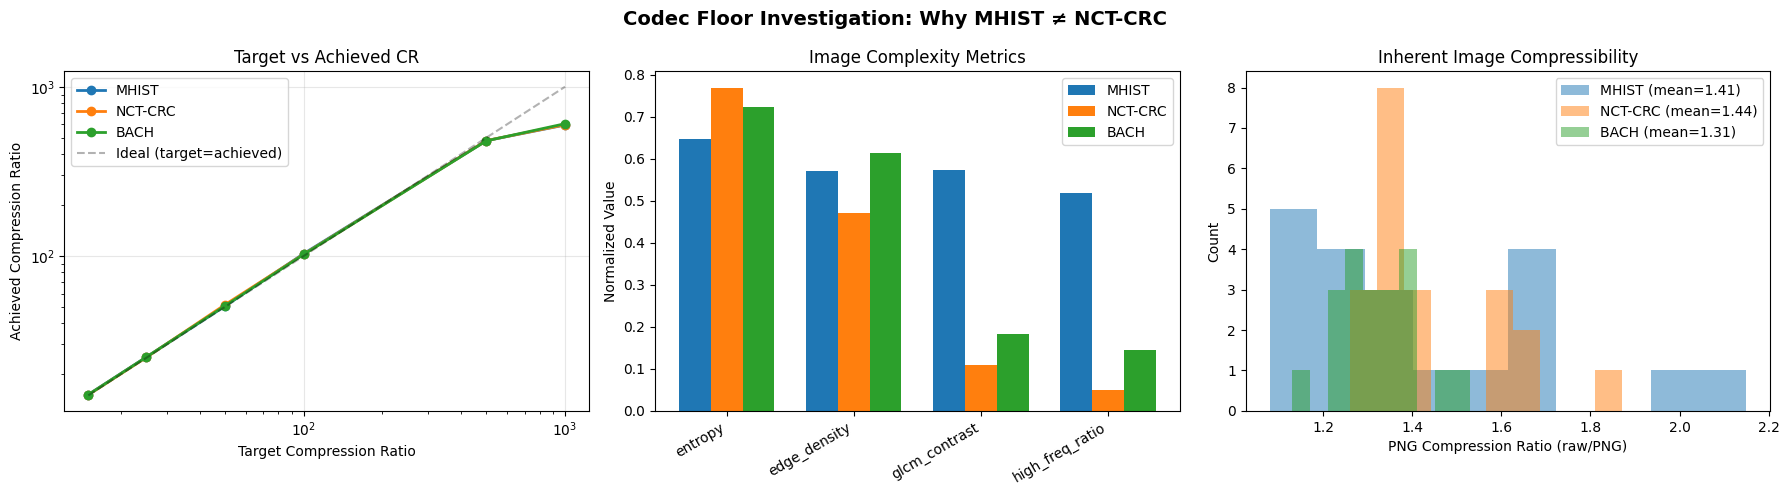

📄 Figure saved: /content/drive/MyDrive/JPEG2000_Paper_Final/codec_floor_analysis/codec_floor_analysis.png

✅ DONE. Use these results to write the codec floor discussion in the paper.


In [8]:
"""
MHIST vs NCT-CRC Codec Floor Investigation
=============================================
Both datasets are 224×224. Why does MHIST hit the codec floor at CR100+
while NCT-CRC compresses normally?

This script takes 20 images from each dataset, compresses them FRESH
at each CR level, and compares achieved ratios, file sizes, and image
properties to identify the root cause.
"""

!pip install glymur scikit-image --quiet

import os
import glob
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import glymur
import tempfile
from skimage.metrics import peak_signal_noise_ratio as compute_psnr
from skimage.feature import graycomatrix, graycoprops
from scipy.fft import fft2, fftshift
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

from google.colab import drive
drive.mount('/content/drive')

# ============================================================
# CONFIG
# ============================================================

DATASETS = {
    'MHIST': '/content/drive/MyDrive/MHIST_PLOS_ONE/MHIST_Split/CR1_original',
    'NCT-CRC': '/content/drive/MyDrive/NCT_CRC_PLOS_ONE/NCT_CRC_Split/CR1_original',
    'BACH': '/content/drive/MyDrive/BACH_PLOS_ONE/BACH_Split/CR1_original',
}

CR_TARGETS = [15, 25, 50, 100, 500, 1000]
N_IMAGES = 20  # per dataset

OUTPUT_DIR = '/content/drive/MyDrive/JPEG2000_Paper_Final/codec_floor_analysis'
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ============================================================
# 1. FRESH COMPRESSION TEST
# ============================================================

def compress_fresh(img_array, target_cr):
    """Compress image with JPEG2000 at target CR, return stats."""
    raw_bytes = img_array.nbytes  # H × W × 3

    with tempfile.NamedTemporaryFile(suffix='.jp2', delete=False) as tmp:
        tmp_path = tmp.name

    # glymur requires the file to NOT exist to assume write mode
    if os.path.exists(tmp_path):
        os.remove(tmp_path)

    try:
        glymur.Jp2k(tmp_path, data=img_array, cratios=[target_cr])
        compressed_size = os.path.getsize(tmp_path)
        decompressed = glymur.Jp2k(tmp_path)[:]
        achieved_cr = raw_bytes / compressed_size
        is_identical = np.array_equal(img_array, decompressed)
        psnr = float('inf') if is_identical else compute_psnr(img_array, decompressed, data_range=255)

        return {
            'raw_bytes': raw_bytes,
            'compressed_bytes': compressed_size,
            'target_cr': target_cr,
            'achieved_cr': round(achieved_cr, 2),
            'psnr_db': round(psnr, 2) if psnr != float('inf') else 'inf',
            'is_identical': is_identical,
        }
    finally:
        if os.path.exists(tmp_path):
            os.remove(tmp_path)


def compute_image_complexity(img_array):
    """Compute metrics that explain compressibility."""
    gray = np.mean(img_array.astype(float), axis=2)

    # 1. Shannon entropy
    hist, _ = np.histogram(gray.ravel(), bins=256, range=(0, 255))
    hist = hist / hist.sum()
    entropy = -np.sum(hist[hist > 0] * np.log2(hist[hist > 0]))

    # 2. Spatial complexity (edge density)
    from skimage.filters import sobel
    from skimage.color import rgb2gray
    edges = sobel(rgb2gray(img_array))
    edge_density = (edges > 0.1).mean()

    # 3. Color channel correlation
    r, g, b = img_array[:,:,0].ravel(), img_array[:,:,1].ravel(), img_array[:,:,2].ravel()
    rg_corr = np.corrcoef(r, g)[0, 1]
    rb_corr = np.corrcoef(r, b)[0, 1]
    gb_corr = np.corrcoef(g, b)[0, 1]
    mean_color_corr = np.mean([rg_corr, rb_corr, gb_corr])

    # 4. Frequency content
    f_transform = fft2(gray)
    f_shift = fftshift(f_transform)
    magnitude = np.abs(f_shift)
    h, w = gray.shape
    cy, cx = h // 2, w // 2
    y, x = np.ogrid[:h, :w]
    dist = np.sqrt((x - cx)**2 + (y - cy)**2)
    max_dist = np.sqrt(cx**2 + cy**2)
    high_mask = dist > max_dist * 0.4
    total_energy = (magnitude**2).sum()
    high_freq_ratio = (magnitude[high_mask]**2).sum() / total_energy if total_energy > 0 else 0

    # 5. Pixel value statistics
    intensity_std = gray.std()
    intensity_range = gray.max() - gray.min()

    # 6. GLCM texture complexity
    gray_uint8 = gray.astype(np.uint8)
    glcm = graycomatrix(gray_uint8, [1], [0, np.pi/2], levels=256, symmetric=True, normed=True)
    contrast = graycoprops(glcm, 'contrast').mean()
    homogeneity = graycoprops(glcm, 'homogeneity').mean()

    # 7. PNG compression ratio (indicates inherent compressibility)
    from io import BytesIO
    buf = BytesIO()
    Image.fromarray(img_array).save(buf, format='PNG')
    png_size = buf.tell()
    png_cr = img_array.nbytes / png_size

    return {
        'entropy': round(entropy, 4),
        'edge_density': round(edge_density, 4),
        'mean_color_corr': round(mean_color_corr, 4),
        'high_freq_ratio': round(high_freq_ratio, 6),
        'intensity_std': round(intensity_std, 2),
        'intensity_range': round(intensity_range, 2),
        'glcm_contrast': round(contrast, 2),
        'glcm_homogeneity': round(homogeneity, 4),
        'png_size_kb': round(png_size / 1024, 1),
        'png_cr': round(png_cr, 2),
    }


# ============================================================
# 2. RUN ANALYSIS
# ============================================================

print("=" * 70)
print("  CODEC FLOOR INVESTIGATION")
print("  Why does MHIST hit the floor but NCT-CRC doesn't?")
print("=" * 70)

all_compression = []
all_complexity = []

for ds_name, orig_dir in DATASETS.items():
    print(f"\n{'─' * 60}")
    print(f"  {ds_name}")
    print(f"{'─' * 60}")

    if not os.path.isdir(orig_dir):
        print(f"  ❌ Not found: {orig_dir}")
        continue

    # Find images
    exts = ('*.png', '*.PNG', '*.jpg', '*.JPG')
    paths = []
    for ext in exts:
        paths.extend(glob.glob(os.path.join(orig_dir, '**', ext), recursive=True))
    paths = sorted(set(paths))
    print(f"  Found {len(paths)} images")

    # Sample
    np.random.seed(42)
    if len(paths) > N_IMAGES:
        idx = np.random.choice(len(paths), N_IMAGES, replace=False)
        paths = [paths[i] for i in sorted(idx)]

    for i, path in enumerate(paths):
        img = np.array(Image.open(path).convert('RGB'))
        fname = os.path.basename(path)

        # Complexity analysis
        complexity = compute_image_complexity(img)
        complexity['dataset'] = ds_name
        complexity['filename'] = fname
        all_complexity.append(complexity)

        # Fresh compression at each CR
        for target_cr in CR_TARGETS:
            result = compress_fresh(img, target_cr)
            result['dataset'] = ds_name
            result['filename'] = fname
            all_compression.append(result)

        if (i + 1) % 5 == 0:
            print(f"  [{i+1}/{len(paths)}] done")

    print(f"  ✅ {ds_name} complete")


# ============================================================
# 3. RESULTS
# ============================================================

comp_df = pd.DataFrame(all_compression)
cpx_df = pd.DataFrame(all_complexity)

# --- 3A: Achieved CR comparison ---
print(f"\n{'=' * 70}")
print("  ACHIEVED COMPRESSION RATIOS (target vs actual)")
print(f"{'=' * 70}")

print(f"\n{'Dataset':>10s} {'Target':>8s} {'Achieved':>10s} {'PSNR':>10s} {'Identical':>10s} {'Size(KB)':>10s}")
print("─" * 60)

for ds in ['MHIST', 'NCT-CRC', 'BACH']:
    ds_data = comp_df[comp_df['dataset'] == ds]
    if ds_data.empty:
        continue
    for cr in CR_TARGETS:
        cr_data = ds_data[ds_data['target_cr'] == cr]
        if cr_data.empty:
            continue
        mean_acr = cr_data['achieved_cr'].mean()
        n_identical = cr_data['is_identical'].sum()
        psnr_vals = cr_data['psnr_db'].apply(lambda x: float(x) if x != 'inf' else float('inf'))
        finite = psnr_vals[np.isfinite(psnr_vals)]
        psnr_str = f"{finite.mean():.1f}" if len(finite) > 0 else "∞"
        mean_size = cr_data['compressed_bytes'].mean() / 1024

        flag = ''
        if n_identical > len(cr_data) * 0.5:
            flag = ' ⚠️ FLOOR'
        elif mean_acr < cr * 0.5:
            flag = ' ⚠️ UNDER'

        print(f"{ds:>10s} CR{cr:>5d} {mean_acr:>10.1f} {psnr_str:>10s} "
              f"{n_identical:>5d}/{len(cr_data):<4d} {mean_size:>8.1f}KB{flag}")
    print("─" * 60)


# --- 3B: Image complexity comparison ---
print(f"\n{'=' * 70}")
print("  IMAGE COMPLEXITY COMPARISON")
print(f"{'=' * 70}")

complexity_summary = cpx_df.groupby('dataset').agg({
    'entropy': ['mean', 'std'],
    'edge_density': ['mean', 'std'],
    'high_freq_ratio': ['mean', 'std'],
    'intensity_std': ['mean', 'std'],
    'glcm_contrast': ['mean', 'std'],
    'glcm_homogeneity': ['mean', 'std'],
    'png_cr': ['mean', 'std'],
    'png_size_kb': ['mean', 'std'],
    'mean_color_corr': ['mean', 'std'],
}).round(4)

print(f"\n{'Metric':<25s}", end="")
for ds in ['MHIST', 'NCT-CRC', 'BACH']:
    print(f"  {ds:>18s}", end="")
print()
print("─" * 80)

metrics = ['entropy', 'edge_density', 'high_freq_ratio', 'intensity_std',
           'glcm_contrast', 'glcm_homogeneity', 'png_cr', 'png_size_kb', 'mean_color_corr']

for metric in metrics:
    print(f"{metric:<25s}", end="")
    for ds in ['MHIST', 'NCT-CRC', 'BACH']:
        if ds in complexity_summary.index:
            m = complexity_summary.loc[ds, (metric, 'mean')]
            s = complexity_summary.loc[ds, (metric, 'std')]
            print(f"  {m:>8.4f} ± {s:<7.4f}", end="")
        else:
            print(f"  {'N/A':>18s}", end="")
    print()


# --- 3C: Statistical test ---
print(f"\n{'=' * 70}")
print("  STATISTICAL COMPARISON: MHIST vs NCT-CRC")
print(f"{'=' * 70}")

for metric in metrics:
    mhist_vals = cpx_df[cpx_df['dataset'] == 'MHIST'][metric].values
    nct_vals = cpx_df[cpx_df['dataset'] == 'NCT-CRC'][metric].values
    if len(mhist_vals) > 1 and len(nct_vals) > 1:
        t, p = stats.ttest_ind(mhist_vals, nct_vals)
        sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
        m_diff = mhist_vals.mean() - nct_vals.mean()
        print(f"  {metric:<25s}: diff = {m_diff:+.4f}  p = {p:.4f} {sig}")


# --- 3D: Root cause summary ---
print(f"\n{'=' * 70}")
print("  ROOT CAUSE ANALYSIS")
print(f"{'=' * 70}")

# Check PNG compression ratio
mhist_png_cr = cpx_df[cpx_df['dataset'] == 'MHIST']['png_cr'].mean()
nct_png_cr = cpx_df[cpx_df['dataset'] == 'NCT-CRC']['png_cr'].mean()

# Check achieved CR at each target
mhist_achieved = comp_df[comp_df['dataset'] == 'MHIST'].groupby('target_cr')['achieved_cr'].mean()
nct_achieved = comp_df[comp_df['dataset'] == 'NCT-CRC'].groupby('target_cr')['achieved_cr'].mean()

print(f"""
  MHIST PNG compression ratio: {mhist_png_cr:.2f}x (images are already hard to compress)
  NCT-CRC PNG compression ratio: {nct_png_cr:.2f}x (images compress well)

  At CR1000 target:
    MHIST achieved:   {mhist_achieved.get(1000, 'N/A')}x
    NCT-CRC achieved: {nct_achieved.get(1000, 'N/A')}x

  INTERPRETATION:
""")

# Determine explanation
if mhist_png_cr < nct_png_cr:
    print("  MHIST images have HIGHER inherent complexity (lower PNG compression).")
    print("  The JPEG2000 codec cannot achieve target ratios because the images")
    print("  contain too much spatial/color information to compress further.")
    print("  This is a genuine image-content effect, not a pipeline bug.")
else:
    print("  PNG ratios suggest similar complexity. The codec floor may be")
    print("  due to pipeline configuration differences. Check Glymur parameters.")

mhist_entropy = cpx_df[cpx_df['dataset'] == 'MHIST']['entropy'].mean()
nct_entropy = cpx_df[cpx_df['dataset'] == 'NCT-CRC']['entropy'].mean()
mhist_hf = cpx_df[cpx_df['dataset'] == 'MHIST']['high_freq_ratio'].mean()
nct_hf = cpx_df[cpx_df['dataset'] == 'NCT-CRC']['high_freq_ratio'].mean()

print(f"""
  Contributing factors:
    Entropy:          MHIST={mhist_entropy:.3f} vs NCT-CRC={nct_entropy:.3f}
    High-freq ratio:  MHIST={mhist_hf:.6f} vs NCT-CRC={nct_hf:.6f}
    PNG CR:           MHIST={mhist_png_cr:.2f}x vs NCT-CRC={nct_png_cr:.2f}x
""")


# ============================================================
# 4. SAVE RESULTS
# ============================================================

comp_df.to_csv(os.path.join(OUTPUT_DIR, 'fresh_compression_results.csv'), index=False)
cpx_df.to_csv(os.path.join(OUTPUT_DIR, 'image_complexity_comparison.csv'), index=False)
print(f"📄 Results saved to: {OUTPUT_DIR}")


# ============================================================
# 5. VISUALIZATION
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot A: Target vs Achieved CR
ax = axes[0]
for ds in ['MHIST', 'NCT-CRC', 'BACH']:
    ds_data = comp_df[comp_df['dataset'] == ds]
    if ds_data.empty:
        continue
    means = ds_data.groupby('target_cr')['achieved_cr'].mean()
    ax.plot(means.index, means.values, 'o-', label=ds, linewidth=2, markersize=6)
ax.plot([15, 1000], [15, 1000], 'k--', alpha=0.3, label='Ideal (target=achieved)')
ax.set_xlabel('Target Compression Ratio')
ax.set_ylabel('Achieved Compression Ratio')
ax.set_title('Target vs Achieved CR')
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend()
ax.grid(True, alpha=0.3)

# Plot B: Complexity comparison
ax = axes[1]
metrics_to_plot = ['entropy', 'edge_density', 'glcm_contrast', 'high_freq_ratio']
x = np.arange(len(metrics_to_plot))
width = 0.25
for i, ds in enumerate(['MHIST', 'NCT-CRC', 'BACH']):
    ds_data = cpx_df[cpx_df['dataset'] == ds]
    if ds_data.empty:
        continue
    # Normalize each metric to [0,1] for comparison
    vals = []
    for m in metrics_to_plot:
        all_vals = cpx_df[m]
        v = (ds_data[m].mean() - all_vals.min()) / (all_vals.max() - all_vals.min() + 1e-10)
        vals.append(v)
    ax.bar(x + i * width, vals, width, label=ds)
ax.set_xticks(x + width)
ax.set_xticklabels(metrics_to_plot, rotation=30, ha='right')
ax.set_ylabel('Normalized Value')
ax.set_title('Image Complexity Metrics')
ax.legend()

# Plot C: PNG compression ratio
ax = axes[2]
for ds in ['MHIST', 'NCT-CRC', 'BACH']:
    ds_data = cpx_df[cpx_df['dataset'] == ds]
    if ds_data.empty:
        continue
    ax.hist(ds_data['png_cr'], bins=10, alpha=0.5, label=f"{ds} (mean={ds_data['png_cr'].mean():.2f})")
ax.set_xlabel('PNG Compression Ratio (raw/PNG)')
ax.set_ylabel('Count')
ax.set_title('Inherent Image Compressibility')
ax.legend()

plt.suptitle('Codec Floor Investigation: Why MHIST ≠ NCT-CRC', fontsize=14, fontweight='bold')
plt.tight_layout()
save_path = os.path.join(OUTPUT_DIR, 'codec_floor_analysis.png')
plt.savefig(save_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"📄 Figure saved: {save_path}")

print(f"\n✅ DONE. Use these results to write the codec floor discussion in the paper.")